<a href="https://colab.research.google.com/github/gonzalesvinicius68-del/LifeSync/blob/main/05-pesquisa-operacional/notebooks/LifeSync_Pesquisa_Campo_e_Operacional.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LifeSync — Pesquisa Operacional e Pesquisa de Campo

**Tema:** distribuição semanal do tempo entre trabalho, estudo, exercício, sono/descanso, lazer e organização pessoal/financeira.

Neste trabalho, desenvolvemos uma análise sobre organização do tempo e planejamento pessoal para apoiar o projeto LifeSync. Organizamos o notebook em cinco partes:

1. **Pesquisa de campo:** análise das 15 respostas que coletamos por meio do Google Forms.
2. **Modelo 1 — maximização:** distribuição de horas semanais para maximizar uma pontuação estimada de produtividade e bem-estar.
3. **Modelo 2 — minimização:** busca por alternativas de menor custo para cumprir metas de estudo, saúde, finanças e lazer.
4. **Problema de transporte:** alocação das horas de três equipes de desenvolvimento aos módulos do LifeSync, com custo mínimo.
5. **Análise de cenários (What-If) e análise crítica:** testes de imprevistos nos três modelos e resposta à pergunta de gestão de riscos.

> **Importante:** os dados da pesquisa são as respostas fornecidas pelos participantes. Já os pontos, custos, eficiências, metas e limites dos modelos matemáticos são premissas estimadas pelo grupo, e não medições feitas com os participantes.

Utilizamos a planilha de respostas como base para a análise e retiramos a coluna de carimbo de data/hora, pois ela não era necessária para os cálculos. Dessa forma, deixamos os dados incorporados ao notebook para que a análise possa ser reproduzida sem expor os horários de envio.


## 1. Formulação matemática

### Modelo 1 — Maximização
**Variáveis de decisão** (horas por semana): $x_1$ Trabalho, $x_2$ Estudo, $x_3$ Exercício, $x_4$ Sono e descanso, $x_5$ Lazer, $x_6$ Organização pessoal/financeira.

**Função objetivo:** $\max Z = \sum_{i=1}^{6} p_i x_i$, em que $p_i$ é a pontuação (0 a 10) de produtividade e satisfação por hora da atividade $i$.

**Restrições:**
- Tempo disponível: $\sum x_i = 140$ (168 h da semana menos 28 h fixas de refeições, deslocamento e higiene).
- Limites por atividade: $l_i \le x_i \le u_i$ (mínimos necessários e máximos saudáveis; refletem retornos decrescentes).
- Carga produtiva máxima: $x_1 + x_2 \le 60$ (evitar sobrecarga).
- Não negatividade: $x_i \ge 0$.

### Modelo 2 — Minimização
**Variáveis:** horas por semana em cada *forma* de cumprir uma meta: estudo (aula presencial, videoaula, grupo de estudo), saúde (academia, caminhada), organização financeira (planilha, app) e lazer (fora de casa, em casa).

**Função objetivo:** $\min C = \sum c_j y_j$, em que $c_j$ é o custo por hora (R$) da forma $j$.

**Restrições:** metas mínimas de "unidades" por categoria, $\sum_{j \in k} e_j y_j \ge M_k$, em que $e_j$ é a eficiência por hora; tempo total $\le 40$ h; limites por forma de execução; $y_j \ge 0$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import linprog
import os

sns.set_theme(style="whitegrid")
os.makedirs("graficos", exist_ok=True)
print("Bibliotecas: numpy, pandas, scipy, matplotlib, seaborn")

Bibliotecas: numpy, pandas, scipy, matplotlib, seaborn


## 2. Pesquisa de campo — respostas reais do Google Forms

Para realizar esta etapa, utilizamos a planilha com **15 respostas e 15 perguntas** que obtivemos por meio do formulário. Retiramos a coluna de carimbo de data/hora para não divulgar informações desnecessárias. Também deixamos os dados incorporados ao notebook, então não é necessário fazer upload de outro arquivo para executar esta versão.

Caso coletemos novas respostas, podemos substituir a base atual pelo novo arquivo exportado do Google Forms.


In [2]:
from io import StringIO

# Respostas reais exportadas do Google Forms (sem carimbo de data/hora).
# Para atualizar a pesquisa futuramente, substitua o conteúdo CSV abaixo
# pelas novas respostas exportadas, mantendo os cabeçalhos das perguntas.
csv_respostas = r'''1. Qual é a sua faixa etária?,"2. Atualmente, qual é a sua principal ocupação?",3. Você considera que consegue organizar bem seu tempo durante a semana?,4. Qual é sua maior dificuldade na organização da rotina?,"5. Em média, quantas horas por dia você dedica ao trabalho?","6. Em média, quantas horas por dia você dedica aos estudos?","7. Quantas horas, em média, você costuma dormir por noite?",8. Com que frequência você pratica atividades físicas?,9. Você consegue reservar tempo para lazer e atividades pessoais?,10. Como você costuma organizar suas tarefas e compromissos?,11. Você costuma controlar seus gastos e organizar suas finanças pessoais?,12. Você já deixou de realizar alguma atividade importante por falta de organização ou planejamento?,"13. Você utilizaria um aplicativo que reunisse organização de tarefas, estudos, trabalho, saúde, lazer e controle financeiro em um só lugar?",14. Quais funcionalidades seriam mais importantes em um aplicativo como o LifeSync?,"15. Na sua opinião, o que um aplicativo de organização pessoal deveria oferecer para facilitar sua rotina?"
18 a 24 anos,Estudo e trabalho,Tenho bastante dificuldade,Conciliar trabalho e estudos,De 7 a 8 horas,De 4 a 5 horas,De 5 a 6 horas,De 3 a 5 vezes por semana,Às vezes,Não utilizo nenhum método específico,Raramente,Algumas vezes,Não,"Organização de tarefas e compromissos, Planejamento de estudos, Organização de descanso e lazer, Controle financeiro pessoal",deveria oferecer agenda para ajudar o dia a dia.
45 a 54 anos,Trabalho em período integral,Na maioria das vezes,Administrar o tempo disponível,De 9 a 10 horas,De 2 a 3 horas,De 7 a 8 horas,Raramente,Às vezes,Não utilizo nenhum método específico,"Sim, frequentemente",Algumas vezes,Sim,"Planejamento de estudos, Controle de horários de trabalho, Organização de descanso e lazer, Metas e acompanhamento de progresso, Relatórios e gráficos de desempenho",Praticidade
18 a 24 anos,Estudo e trabalho,Na maioria das vezes,Organizar compromissos,Até 4 horas,De 2 a 3 horas,De 7 a 8 horas,De 3 a 5 vezes por semana,Às vezes,Memorizo minhas tarefas,Às vezes,Algumas vezes,Sim,"Organização de tarefas e compromissos, Planejamento de estudos, Controle de horários de trabalho, Acompanhamento de atividades físicas, Organização de descanso e lazer, Controle financeiro pessoal, Metas e acompanhamento de progresso, Relatórios e gráficos de desempenho","Acredito que um aplicativo que ajude a conciliar as tarefas do dia a dia, e ao mesmo tempo junte às atividades fisicas que são de extrema importancia junto ao descanso seriam bem úteis. "
18 a 24 anos,Estudo e trabalho,Tenho bastante dificuldade,Conciliar trabalho e estudos,De 7 a 8 horas,De 4 a 5 horas,Menos de 5 horas,De 3 a 5 vezes por semana,Às vezes,Não utilizo nenhum método específico,Às vezes,Frequentemente,Sim,"Organização de tarefas e compromissos, Planejamento de estudos, Controle de horários de trabalho, Acompanhamento de atividades físicas, Organização de descanso e lazer, Controle financeiro pessoal, Metas e acompanhamento de progresso, Relatórios e gráficos de desempenho",ser patrício de usar
18 a 24 anos,Estudo e trabalho,Às vezes,Conciliar trabalho e estudos,De 5 a 6 horas,De 2 a 3 horas,De 5 a 6 horas,Raramente,Frequentemente,Planilhas,"Sim, frequentemente",Algumas vezes,Sim,"Organização de tarefas e compromissos, Planejamento de estudos, Acompanhamento de atividades físicas","Notificação contante, sobre a tarefa agendada"
Menos de 18 anos,Estudante,"Sim, muito bem",Não tenho dificuldades significativas,Não trabalho atualmente,Até 1 hora,De 7 a 8 horas,De 3 a 5 vezes por semana,Frequentemente,Memorizo minhas tarefas,Não faço esse controle,Raramente,Não,"Organização de tarefas e compromissos, Planejamento de estudos, Controle de horários de trabalho, Acompanhamento de atividades físicas, Organização de descanso e lazer, Controle financeiro pessoal, Metas e acompanhamento de progresso, Relatórios e gráficos de desempenho","Um aplicativo de organização pessoal deveria oferecer agenda, lembretes, lista de tarefas, planejamento semanal, controle financeiro e acompanhamento de metas. Além disso, deveria ser simples e fácil de usar, ajudando a organizar os compromissos, administrar melhor o tempo e conciliar as responsabilidades do dia a dia."
45 a 54 anos,Estudo e trabalho,Na maioria das vezes,Conciliar trabalho e estudos,De 7 a 8 horas,De 2 a 3 horas,De 7 a 8 horas,1 a 2 vezes por semana,Às vezes,Não utilizo nenhum método específico,"Sim, frequentemente",Frequentemente,Sim,Organização de tarefas e compromissos,Um alarme
18 a 24 anos,Estudo e trabalho,Na maioria das vezes,Ter tempo para descansar e aproveitar o lazer,De 9 a 10 horas,De 2 a 3 horas,De 5 a 6 horas,1 a 2 vezes por semana,Às vezes,Memorizo minhas tarefas,Às vezes,Algumas vezes,Sim,Metas e acompanhamento de progresso,Uma interface de fácil entendimento
25 a 34 anos,Estou procurando emprego,Às vezes,Manter uma rotina de exercícios,Não trabalho atualmente,Não estudo atualmente,De 5 a 6 horas,Nunca,Às vezes,Aplicativo de calendário,Às vezes,Algumas vezes,Sim,"Organização de tarefas e compromissos, Planejamento de estudos, Controle de horários de trabalho, Acompanhamento de atividades físicas, Organização de descanso e lazer, Controle financeiro pessoal",Ter notificações
18 a 24 anos,Trabalho em período integral,Às vezes,Manter uma rotina de exercícios,Mais de 10 horas,De 2 a 3 horas,De 5 a 6 horas,Raramente,Às vezes,Memorizo minhas tarefas,"Sim, frequentemente",Algumas vezes,Não,Organização de tarefas e compromissos,Não sei 🤷🏻‍♂️
18 a 24 anos,Estudo e trabalho,Às vezes,Administrar o tempo disponível,De 7 a 8 horas,De 2 a 3 horas,De 5 a 6 horas,Raramente,Às vezes,Agenda física ou caderno,Às vezes,Algumas vezes,Sim,"Organização de tarefas e compromissos, Planejamento de estudos, Controle financeiro pessoal",Deveria registrar automaticamente o compromisso que eu comentei com alguém e me lembrar várias vzs antes
18 a 24 anos,Estudante,Às vezes,Administrar o tempo disponível,Não trabalho atualmente,De 2 a 3 horas,De 9 a 10 horas,De 3 a 5 vezes por semana,Frequentemente,Memorizo minhas tarefas,Às vezes,Algumas vezes,Talvez,"Organização de tarefas e compromissos, Planejamento de estudos, Controle de horários de trabalho, Acompanhamento de atividades físicas, Organização de descanso e lazer, Controle financeiro pessoal, Metas e acompanhamento de progresso, Relatórios e gráficos de desempenho",Tudo
18 a 24 anos,Trabalho em período integral,Tenho bastante dificuldade,Administrar o tempo disponível,De 7 a 8 horas,Até 1 hora,De 7 a 8 horas,Raramente,Raramente,Memorizo minhas tarefas,"Sim, frequentemente",Algumas vezes,Não,Organização de tarefas e compromissos,"Como organizar a rotina de trabalho, estudos e lazer de uma forma simples"
18 a 24 anos,Trabalho em período integral,Tenho bastante dificuldade,Administrar o tempo disponível,De 9 a 10 horas,Não estudo atualmente,Menos de 5 horas,De 3 a 5 vezes por semana,Às vezes,Memorizo minhas tarefas,"Sim, frequentemente",Algumas vezes,Talvez,"Organização de tarefas e compromissos, Organização de descanso e lazer, Controle financeiro pessoal, Metas e acompanhamento de progresso","Praticidade,personalização e adaptabilidade pra:

Praticidade pra nao ser algo complexo pra quem quer organizar o tempo, ser simples de entender e simples de usar

Personalização pra poder adaptar a própria rotina e poder alterar de forma simples

Adaptabilidade pra compreender e entender a rotina e limitação das pessoas ,nao so montar uma agenda e fazer com que a pessoa tenha que se empenhar mais pra poder conseguir cumpri-la, isso quebra o propósito do aplicativo "
18 a 24 anos,Estudo e trabalho,Na maioria das vezes,Administrar o tempo disponível,De 5 a 6 horas,De 2 a 3 horas,De 5 a 6 horas,De 3 a 5 vezes por semana,Sempre,Agenda física ou caderno,"Sim, frequentemente",Algumas vezes,Talvez,"Planejamento de estudos, Metas e acompanhamento de progresso","Fácil acesso em qualquer lugar, celular, computador, site. E notificações de agenda, sempre esta alertando sobre sua agenda não deixando você esquecer."
'''

df_pesquisa = pd.read_csv(StringIO(csv_respostas))
df_pesquisa = df_pesquisa.dropna(how="all").drop_duplicates().copy()

print(f"Respostas válidas analisadas: {len(df_pesquisa)}")
print(f"Perguntas analisadas: {len(df_pesquisa.columns)}")
display(df_pesquisa.head())


Respostas válidas analisadas: 15
Perguntas analisadas: 15


,1. Qual é a sua faixa etária?,"2. Atualmente, qual é a sua principal ocupação?",3. Você considera que consegue organizar bem seu tempo durante a semana?,4. Qual é sua maior dificuldade na organização da rotina?,"5. Em média, quantas horas por dia você dedica ao trabalho?","6. Em média, quantas horas por dia você dedica aos estudos?","7. Quantas horas, em média, você costuma dormir por noite?",8. Com que frequência você pratica atividades físicas?,9. Você consegue reservar tempo para lazer e atividades pessoais?,10. Como você costuma organizar suas tarefas e compromissos?,11. Você costuma controlar seus gastos e organizar suas finanças pessoais?,12. Você já deixou de realizar alguma atividade importante por falta de organização ou planejamento?,"13. Você utilizaria um aplicativo que reunisse organização de tarefas, estudos, trabalho, saúde, lazer e controle financeiro em um só lugar?",14. Quais funcionalidades seriam mais importantes em um aplicativo como o LifeSync?,"15. Na sua opinião, o que um aplicativo de organização pessoal deveria oferecer para facilitar sua rotina?"
0,18 a 24 anos,Estudo e trabalho,Tenho bastante dificuldade,Conciliar trabalho e estudos,De 7 a 8 horas,De 4 a 5 horas,De 5 a 6 horas,De 3 a 5 vezes por semana,Às vezes,Não utilizo nenhum método específico,Raramente,Algumas vezes,Não,"Organização de tarefas e compromissos, Planeja...",deveria oferecer agenda para ajudar o dia a dia.
1,45 a 54 anos,Trabalho em período integral,Na maioria das vezes,Administrar o tempo disponível,De 9 a 10 horas,De 2 a 3 horas,De 7 a 8 horas,Raramente,Às vezes,Não utilizo nenhum método específico,"Sim, frequentemente",Algumas vezes,Sim,"Planejamento de estudos, Controle de horários ...",Praticidade
2,18 a 24 anos,Estudo e trabalho,Na maioria das vezes,Organizar compromissos,Até 4 horas,De 2 a 3 horas,De 7 a 8 horas,De 3 a 5 vezes por semana,Às vezes,Memorizo minhas tarefas,Às vezes,Algumas vezes,Sim,"Organização de tarefas e compromissos, Planeja...",Acredito que um aplicativo que ajude a concili...
3,18 a 24 anos,Estudo e trabalho,Tenho bastante dificuldade,Conciliar trabalho e estudos,De 7 a 8 horas,De 4 a 5 horas,Menos de 5 horas,De 3 a 5 vezes por semana,Às vezes,Não utilizo nenhum método específico,Às vezes,Frequentemente,Sim,"Organização de tarefas e compromissos, Planeja...",ser patrício de usar
4,18 a 24 anos,Estudo e trabalho,Às vezes,Conciliar trabalho e estudos,De 5 a 6 horas,De 2 a 3 horas,De 5 a 6 horas,Raramente,Frequentemente,Planilhas,"Sim, frequentemente",Algumas vezes,Sim,"Organização de tarefas e compromissos, Planeja...","Notificação contante, sobre a tarefa agendada"


### 2.1 Conferência e limpeza dos dados

Nesta etapa, removemos as linhas totalmente vazias e as duplicatas idênticas. Mantivemos as respostas em branco como dados ausentes, sem preencher informações por conta própria. A base contém respostas categóricas e uma pergunta aberta.


In [3]:
print("Valores ausentes por pergunta:")
display(df_pesquisa.isna().sum().to_frame("Valores ausentes"))

print("Quantidade de respostas válidas:", len(df_pesquisa))
print("Duplicatas restantes:", int(df_pesquisa.duplicated().sum()))


Valores ausentes por pergunta:


,Valores ausentes
1. Qual é a sua faixa etária?,0
"2. Atualmente, qual é a sua principal ocupação?",0
3. Você considera que consegue organizar bem seu tempo durante a semana?,0
4. Qual é sua maior dificuldade na organização da rotina?,0
"5. Em média, quantas horas por dia você dedica ao trabalho?",0
"6. Em média, quantas horas por dia você dedica aos estudos?",0
"7. Quantas horas, em média, você costuma dormir por noite?",0
8. Com que frequência você pratica atividades físicas?,0
9. Você consegue reservar tempo para lazer e atividades pessoais?,0
10. Como você costuma organizar suas tarefas e compromissos?,0


Quantidade de respostas válidas: 15
Duplicatas restantes: 0


### 2.2 Análise descritiva e frequências

Nesta parte, organizamos as respostas em tabelas com a quantidade e o percentual de participantes em cada alternativa. Calculamos os percentuais considerando as respostas válidas de cada pergunta.


In [4]:
colunas = df_pesquisa.columns.tolist()
coluna_aberta = colunas[-1]
coluna_multiselect = colunas[-2]
colunas_categoricas = colunas[:-1]

def tabela_frequencia(coluna):
    freq = df_pesquisa[coluna].fillna("Não respondeu").value_counts()
    tabela = pd.DataFrame({
        "Quantidade": freq,
        "Percentual (%)": (freq / len(df_pesquisa) * 100).round(1)
    })
    return tabela

for coluna in colunas[:-2]:
    print(f"\\n{coluna}")
    display(tabela_frequencia(coluna))


\n1. Qual é a sua faixa etária?


,Quantidade,Percentual (%)
1. Qual é a sua faixa etária?,,
18 a 24 anos,11,73.3
45 a 54 anos,2,13.3
Menos de 18 anos,1,6.7
25 a 34 anos,1,6.7


\n2. Atualmente, qual é a sua principal ocupação?


,Quantidade,Percentual (%)
"2. Atualmente, qual é a sua principal ocupação?",,
Estudo e trabalho,8,53.3
Trabalho em período integral,4,26.7
Estudante,2,13.3
Estou procurando emprego,1,6.7


\n3. Você considera que consegue organizar bem seu tempo durante a semana?


,Quantidade,Percentual (%)
3. Você considera que consegue organizar bem seu tempo durante a semana?,,
Na maioria das vezes,5,33.3
Às vezes,5,33.3
Tenho bastante dificuldade,4,26.7
"Sim, muito bem",1,6.7


... (16 outputs left out)

\n12. Você já deixou de realizar alguma atividade importante por falta de organização ou planejamento?


,Quantidade,Percentual (%)
12. Você já deixou de realizar alguma atividade importante por falta de organização ou planejamento?,,
Algumas vezes,12,80.0
Frequentemente,2,13.3
Raramente,1,6.7


\n13. Você utilizaria um aplicativo que reunisse organização de tarefas, estudos, trabalho, saúde, lazer e controle financeiro em um só lugar?


,Quantidade,Percentual (%)
"13. Você utilizaria um aplicativo que reunisse organização de tarefas, estudos, trabalho, saúde, lazer e controle financeiro em um só lugar?",,
Sim,8,53.3
Não,4,26.7
Talvez,3,20.0


### 2.3 Gráficos da pesquisa de campo

Criamos os gráficos abaixo para facilitar a visualização dos principais resultados da pesquisa. Eles representam somente as respostas deste grupo de 15 participantes, portanto não devem ser considerados uma estimativa de toda a população.


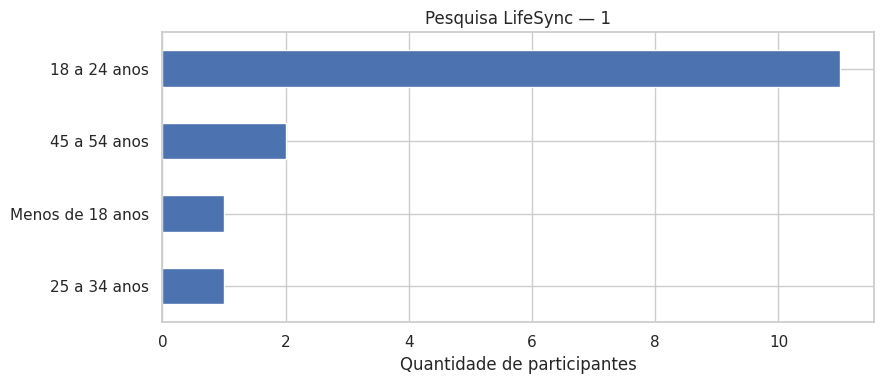

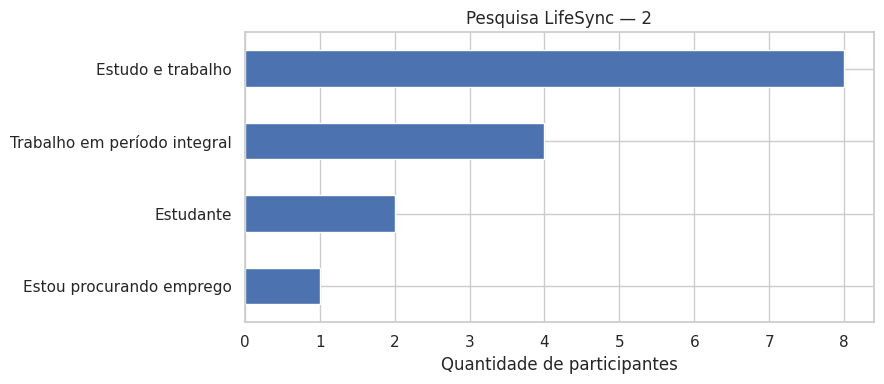

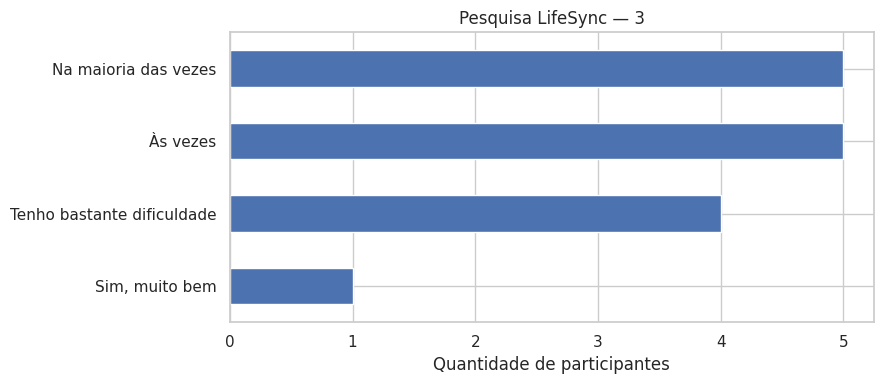

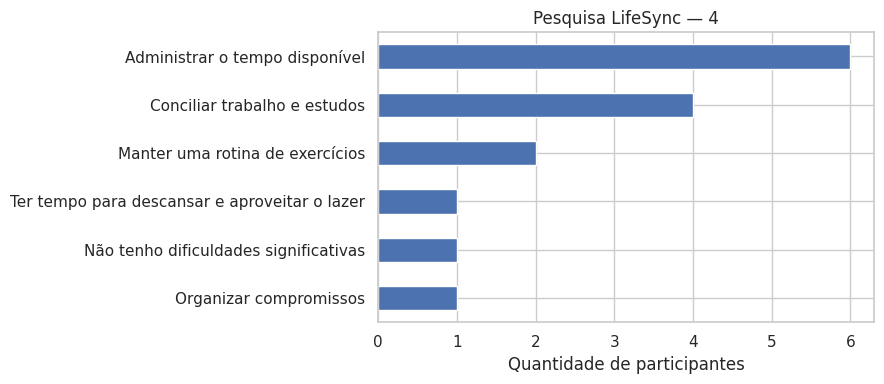

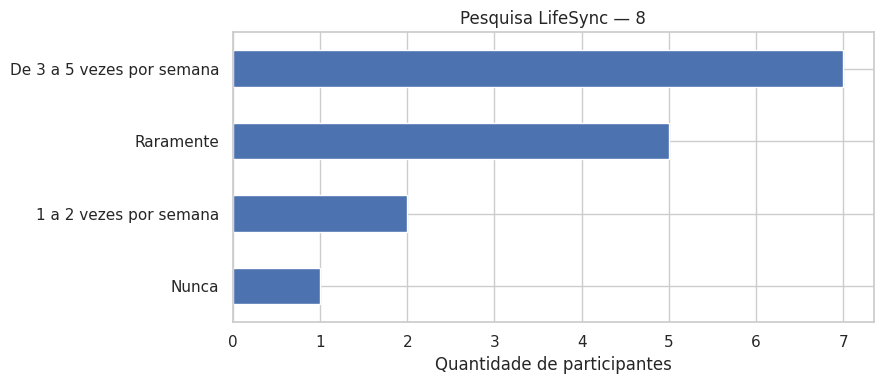

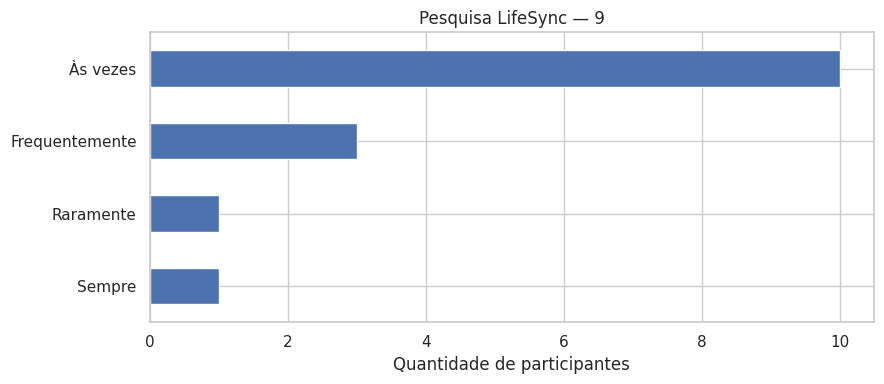

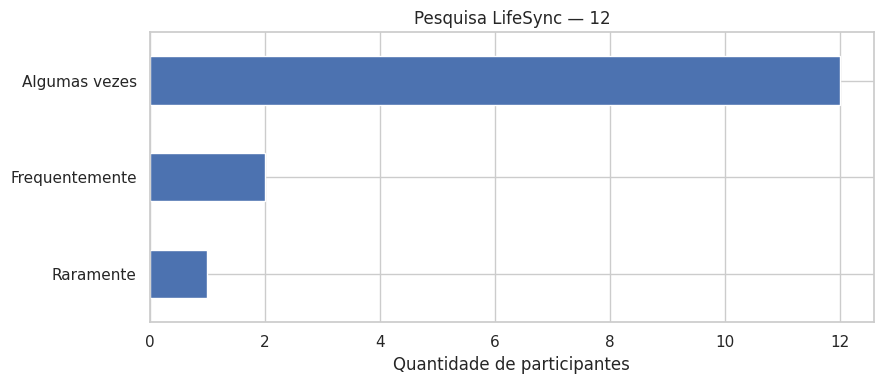

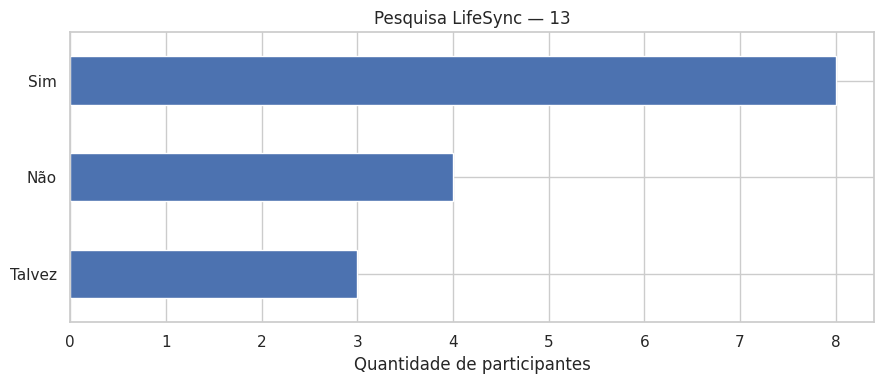

Funcionalidades mais selecionadas (uma pessoa pode selecionar várias):


,Quantidade de marcações,Participantes (%)
14. Quais funcionalidades seriam mais importantes em um aplicativo como o LifeSync?,,
Organização de tarefas e compromissos,12,80.0
Planejamento de estudos,10,66.7
Organização de descanso e lazer,8,53.3
Controle financeiro pessoal,8,53.3
Metas e acompanhamento de progresso,8,53.3
Controle de horários de trabalho,6,40.0
Acompanhamento de atividades físicas,6,40.0
Relatórios e gráficos de desempenho,5,33.3


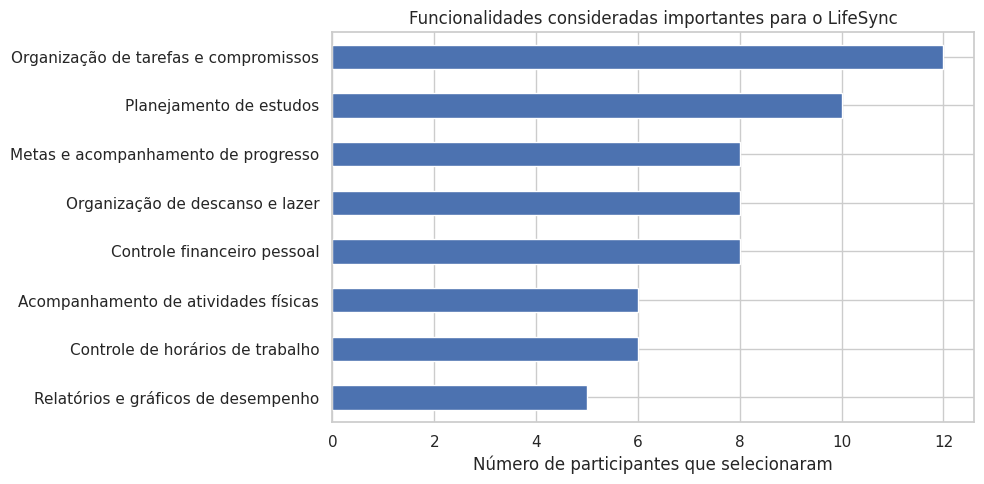

Respostas abertas à pergunta 15:
1. deveria oferecer agenda para ajudar o dia a dia.
2. Praticidade
3. Acredito que um aplicativo que ajude a conciliar as tarefas do dia a dia, e ao mesmo tempo junte às atividades fisicas que são de extrema importancia junto ao descanso seriam bem úteis. 
4. ser patrício de usar
5. Notificação contante, sobre a tarefa agendada
6. Um aplicativo de organização pessoal deveria oferecer agenda, lembretes, lista de tarefas, planejamento semanal, controle financeiro e acompanhamento de metas. Além disso, deveria ser simples e fácil de usar, ajudando a organizar os compromissos, administrar melhor o tempo e conciliar as responsabilidades do dia a dia.
7. Um alarme 
8. Uma interface de fácil entendimento 
9. Ter notificações 
10. Não sei 🤷🏻‍♂️
11. Deveria registrar automaticamente o compromisso que eu comentei com alguém e me lembrar várias vzs antes
12. Tudo 
13. Como organizar a rotina de trabalho, estudos e lazer de uma forma simples
14. Praticidade,persona

In [5]:
# Gráficos das principais perguntas
perguntas_graficos = [colunas[0], colunas[1], colunas[2], colunas[3],
                      colunas[7], colunas[8], colunas[11], colunas[12]]

for i, coluna in enumerate(perguntas_graficos, start=1):
    freq = df_pesquisa[coluna].fillna("Não respondeu").value_counts()
    plt.figure(figsize=(9, 4))
    freq.sort_values().plot(kind="barh")
    plt.title(f"Pesquisa LifeSync — {coluna.split('.')[0]}")
    plt.xlabel("Quantidade de participantes")
    plt.ylabel("")
    plt.tight_layout()
    plt.savefig(f"graficos/pesquisa_{i:02d}.png", dpi=150)
    plt.show()

# Funcionalidades: a pergunta permite marcar mais de uma opção.
funcionalidades = (df_pesquisa[coluna_multiselect].dropna()
                   .str.split(", ").explode().str.strip())
freq_func = funcionalidades.value_counts()
tabela_func = pd.DataFrame({
    "Quantidade de marcações": freq_func,
    "Participantes (%)": (freq_func / len(df_pesquisa) * 100).round(1)
})
print("Funcionalidades mais selecionadas (uma pessoa pode selecionar várias):")
display(tabela_func)

plt.figure(figsize=(10, 5))
freq_func.sort_values().plot(kind="barh")
plt.title("Funcionalidades consideradas importantes para o LifeSync")
plt.xlabel("Número de participantes que selecionaram")
plt.ylabel("")
plt.tight_layout()
plt.savefig("graficos/pesquisa_funcionalidades.png", dpi=150)
plt.show()

print("Respostas abertas à pergunta 15:")
for n, resposta in enumerate(df_pesquisa[coluna_aberta].dropna(), start=1):
    print(f"{n}. {resposta}")


## 3. Modelo 1 — Maximização (3 cenários)

In [6]:
atividades = ["Trabalho", "Estudo", "Exercício", "Sono e descanso", "Lazer", "Organização pessoal/financeira"]
pontos = np.array([6.0, 7.0, 8.0, 9.0, 7.5, 6.5])     # premissa do grupo: pontos (0 a 10) por hora de cada atividade
DISPONIVEL = 140                                       # 168 h - 28 h fixas
LIMITE_CARGA = 60                                      # x1 + x2 <= 60

cenarios = {
    #               (min, max) por atividade, na ordem de 'atividades'
    "Estudante":    [(10, 20), (20, 35), (3, 8), (49, 63), (8, 25), (2, 5)],
    "Trabalhador":  [(40, 48), (5, 15),  (3, 8), (49, 63), (8, 25), (2, 5)],
    "Equilibrado":  [(30, 40), (10, 20), (4, 8), (49, 63), (10, 25), (2, 5)],
}

def resolver_maximizacao(limites):
    c = -pontos                                        # linprog minimiza, então maximizamos -Z
    A_eq, b_eq = [np.ones(6)], [DISPONIVEL]
    A_ub, b_ub = [[1, 1, 0, 0, 0, 0]], [LIMITE_CARGA]
    return linprog(c, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=b_eq, bounds=limites, method="highs")

resultados, extras = {}, {}
for nome, lim in cenarios.items():
    r = resolver_maximizacao(lim)
    assert r.success, f"Cenário {nome} sem solução: {r.message}"
    resultados[nome] = r.x
    extras[nome] = {"Z": -r.fun,
                    "valor_hora_extra": -r.eqlin.marginals[0],          # preço-sombra do tempo
                    "folga_carga": LIMITE_CARGA - (r.x[0] + r.x[1])}

tabela = pd.DataFrame(resultados, index=atividades).round(1)
tabela.loc["PONTUAÇÃO Z"] = [round(extras[n]["Z"], 1) for n in cenarios]
tabela

,Estudante,Trabalhador,Equilibrado
Trabalho,10.0,40.0,30.0
Estudo,32.0,5.0,12.0
Exercício,8.0,8.0,8.0
Sono e descanso,63.0,63.0,63.0
Lazer,25.0,22.0,25.0
Organização pessoal/financeira,2.0,2.0,2.0
PONTUAÇÃO Z,1115.5,1084.0,1095.5


In [7]:
print("Preço-sombra de 1 hora extra de tempo (ganho em pontos) e folga da restrição de carga produtiva:\n")
for n, e in extras.items():
    print(f"{n:12s} | +1 h disponível → +{e['valor_hora_extra']:.2f} pontos | folga da carga: {e['folga_carga']:.1f} h")

Preço-sombra de 1 hora extra de tempo (ganho em pontos) e folga da restrição de carga produtiva:

Estudante    | +1 h disponível → +7.00 pontos | folga da carga: 18.0 h
Trabalhador  | +1 h disponível → +7.50 pontos | folga da carga: 15.0 h
Equilibrado  | +1 h disponível → +7.00 pontos | folga da carga: 18.0 h


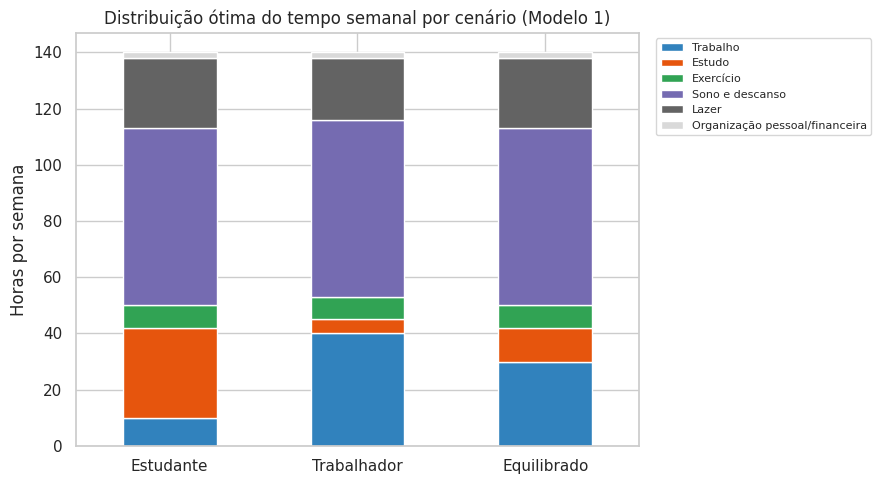

In [8]:
ax = tabela.drop("PONTUAÇÃO Z").T.plot(kind="bar", stacked=True, figsize=(9, 5), colormap="tab20c")
ax.set_title("Distribuição ótima do tempo semanal por cenário (Modelo 1)")
ax.set_ylabel("Horas por semana"); ax.set_xlabel("")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.xticks(rotation=0); plt.tight_layout()
plt.savefig("graficos/PO_01_maximizacao_cenarios.png", dpi=150); plt.show()

### Análise de sensibilidade (Modelo 1)

Nesta análise, verificamos como a pontuação ótima muda quando alteramos algumas condições do modelo, como o limite de horas de sono de 63 para 56 horas e a pontuação atribuída ao lazer.


In [9]:
base = cenarios["Equilibrado"]
linhas = []
for sono_max in [49, 56, 63]:
    lim = list(base); lim[3] = (49, sono_max)
    r = resolver_maximizacao(lim)
    linhas.append({"Parâmetro": f"Sono máx = {sono_max} h", "Z ótimo": round(-r.fun, 1) if r.success else None,
                   "Viável": r.success})
for p_lazer in [6.0, 7.5, 9.5]:
    pontos_original = pontos.copy(); pontos[4] = p_lazer
    r = resolver_maximizacao(base)
    linhas.append({"Parâmetro": f"Pontos do lazer = {p_lazer}", "Z ótimo": round(-r.fun, 1), "Viável": r.success,
                   "Lazer ótimo (h)": round(r.x[4], 1)})
    pontos = pontos_original
pd.DataFrame(linhas)

,Parâmetro,Z ótimo,Viável,Lazer ótimo (h)
0,Sono máx = 49 h,1063.0,True,NaN
1,Sono máx = 56 h,1081.5,True,NaN
2,Sono máx = 63 h,1095.5,True,NaN
3,Pontos do lazer = 6.0,1067.5,True,14.0
4,Pontos do lazer = 7.5,1095.5,True,25.0
5,Pontos do lazer = 9.5,1145.5,True,25.0


## 4. Modelo 2 — Minimização de custo

In [10]:
formas = ["Estudo: aula presencial", "Estudo: videoaula", "Estudo: grupo de estudo",
          "Saúde: academia", "Saúde: caminhada ao ar livre",
          "Finanças: planilha manual", "Finanças: app (tipo LifeSync)",
          "Lazer: fora de casa", "Lazer: em casa"]
custo_h  = np.array([12.0, 3.0, 5.0, 6.0, 0.0, 0.0, 2.0, 20.0, 2.0])   # premissa do grupo: custo em R$ por hora
eficiencia = np.array([1.0, 0.7, 0.9, 1.0, 0.6, 0.5, 1.2, 1.0, 0.8])   # premissa do grupo: unidades de benefício por hora
categoria = ["Estudo"]*3 + ["Saúde"]*2 + ["Finanças"]*2 + ["Lazer"]*2
metas = {"Estudo": 12, "Saúde": 4, "Finanças": 3, "Lazer": 6}          # unidades mínimas por semana
TEMPO_MAX = 40                                                          # horas semanais disponíveis
limite_forma = [(0, 8), (0, 10), (0, 6), (0, 5), (0, 6), (0, 6), (0, 4), (0, 6), (0, 10)]

A_ub, b_ub = [], []
for cat, minimo in metas.items():                                       # eficiência*horas >= meta  ->  -eficiência*horas <= -meta
    A_ub.append([-e if c == cat else 0 for e, c in zip(eficiencia, categoria)]); b_ub.append(-minimo)
A_ub.append([1] * len(formas)); b_ub.append(TEMPO_MAX)                  # limite de tempo

r2 = linprog(custo_h, A_ub=A_ub, b_ub=b_ub, bounds=limite_forma, method="highs")
assert r2.success, r2.message

res2 = pd.DataFrame({"Forma": formas, "Categoria": categoria, "Horas/semana": r2.x.round(2),
                     "Custo (R$)": (r2.x * custo_h).round(2)})
print(f"Custo mínimo semanal: R$ {r2.fun:.2f} | Tempo usado: {r2.x.sum():.1f} h de {TEMPO_MAX} h")
res2[res2["Horas/semana"] > 0]

Custo mínimo semanal: R$ 75.18 | Tempo usado: 35.5 h de 40 h


,Forma,Categoria,Horas/semana,Custo (R$)
1,Estudo: videoaula,Estudo,10.00,30.00
2,Estudo: grupo de estudo,Estudo,5.56,27.78
3,Saúde: academia,Saúde,0.40,2.40
4,Saúde: caminhada ao ar livre,Saúde,6.00,0.00
5,Finanças: planilha manual,Finanças,6.00,0.00
8,Lazer: em casa,Lazer,7.50,15.00


In [11]:
# Preço-sombra das metas: quanto custa, em R$, aumentar a meta de cada categoria em 1 unidade
limite_sem_app = list(limite_forma); limite_sem_app[6] = (0, 0)   # cenário sem o app
sombra = pd.Series(-r2.ineqlin.marginals[:len(metas)], index=list(metas)).round(2)
print("Custo extra (R$) por +1 unidade de meta:")
print(sombra)

# Variante do Modelo 2: minimizar o TEMPO total, com orçamento semanal limitado
ORCAMENTO = 120.0
A_ub_t = [row[:] if isinstance(row, list) else list(row) for row in A_ub[:len(metas)]]
b_ub_t = b_ub[:len(metas)]
A_ub_t.append(list(custo_h)); b_ub_t.append(ORCAMENTO)            # custo total <= orçamento
horas = np.ones(len(formas))

def min_tempo(limites):
    return linprog(horas, A_ub=A_ub_t, b_ub=b_ub_t, bounds=limites, method="highs")

com_app = min_tempo(limite_forma)
sem_app = min_tempo(limite_sem_app)
print(f"Objetivo CUSTO  → R$ {r2.fun:.2f}/semana usando {r2.x.sum():.1f} h")
assert com_app.success and sem_app.success, "Um dos cenários de tempo não possui solução viável."
print(f"Objetivo TEMPO (orçamento R$ {ORCAMENTO:.0f}) → COM opção de app: {com_app.fun:.1f} h (custo estimado R$ {com_app.x @ custo_h:.2f}) | SEM opção de app: {sem_app.fun:.1f} h (custo estimado R$ {sem_app.x @ custo_h:.2f})")
print(f"Diferença de tempo simulada com a opção de app: {sem_app.fun - com_app.fun:.1f} h por semana")

Custo extra (R$) por +1 unidade de meta:
Estudo      5.56
Saúde       6.00
Finanças    0.00
Lazer       2.50
dtype: float64
Objetivo CUSTO  → R$ 75.18/semana usando 35.5 h
Objetivo TEMPO (orçamento R$ 120) → COM opção de app: 28.4 h (custo estimado R$ 120.00) | SEM opção de app: 31.7 h (custo estimado R$ 120.00)
Diferença de tempo simulada com a opção de app: 3.2 h por semana


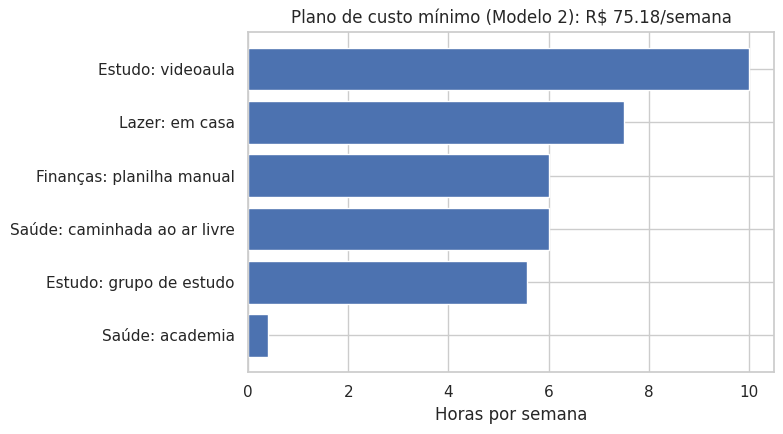

In [12]:
dados_plot = res2[res2["Horas/semana"] > 0].sort_values("Horas/semana")
plt.figure(figsize=(8, 4.5))
plt.barh(dados_plot["Forma"], dados_plot["Horas/semana"], color="#4C72B0")
plt.title(f"Plano de custo mínimo (Modelo 2): R$ {r2.fun:.2f}/semana"); plt.xlabel("Horas por semana")
plt.tight_layout(); plt.savefig("graficos/PO_02_minimizacao_custo.png", dpi=150); plt.show()

## 5. Problema de Transporte — alocação de equipes aos módulos do LifeSync

**Contexto:** para desenvolver a plataforma, o LifeSync precisa distribuir as horas semanais de três equipes (interna, freelancers e squad parceiro) entre três módulos (Tarefas e Agenda, Módulo Financeiro e Segurança e Privacidade). Cada equipe tem uma capacidade semanal e um custo por hora diferente em cada módulo. O objetivo é atender a necessidade de horas de cada módulo com o menor custo semanal.

**Variáveis de decisão:** $x_{ij}$ = horas por semana da equipe $i$ alocadas ao módulo $j$.

**Função objetivo:** $\min Z = \sum_{i=1}^{3}\sum_{j=1}^{3} c_{ij}\,x_{ij}$, em que $c_{ij}$ é o custo por hora (R$) da equipe $i$ no módulo $j$.

**Restrições:**
- Oferta: $\sum_{j} x_{ij} \le O_i$ (a equipe não pode ultrapassar a sua capacidade semanal);
- Demanda: $\sum_{i} x_{ij} = D_j$ (cada módulo recebe exatamente as horas de que precisa);
- Não negatividade: $x_{ij} \ge 0$.

Capacidades (160, 100 e 120 h) e necessidades (120, 140 e 60 h) são premissas do grupo, assim como os custos por hora. Como a oferta total (380 h) supera a demanda (320 h), o problema tem folga no cenário base.

In [ ]:
# Premissas do grupo (didáticas): custo por hora alocada e capacidades semanais
equipes = ["Equipe interna", "Freelancers", "Squad parceiro"]
modulos = ["Tarefas e Agenda", "Módulo Financeiro", "Segurança e Privacidade"]

custo_transp = np.array([      # R$ por hora: equipe i -> módulo j
    [70, 75,  65],             # Equipe interna: mais aderente a segurança
    [80, 85, 100],             # Freelancers: caros em segurança
    [55, 60,  90],             # Squad parceiro: barato, menos aderente a segurança
], dtype=float)
oferta_base  = np.array([160, 100, 120], dtype=float)   # horas/semana por equipe
demanda_mod  = np.array([120, 140, 60], dtype=float)    # horas/semana exigidas por módulo (exato)

def resolver_transporte(oferta, custos=custo_transp, demanda=demanda_mod):
    m, n = custos.shape
    A_ub = np.zeros((m, m * n)); A_eq = np.zeros((n, m * n))
    for i in range(m): A_ub[i, i * n:(i + 1) * n] = 1      # oferta: soma da linha <= capacidade
    for j in range(n): A_eq[j, j::n] = 1                   # demanda: soma da coluna == necessidade
    return linprog(custos.flatten(), A_ub=A_ub, b_ub=oferta, A_eq=A_eq, b_eq=demanda,
                   bounds=(0, None), method="highs")

r_t = resolver_transporte(oferta_base)
assert r_t.success, r_t.message
plano_base = pd.DataFrame(r_t.x.reshape(3, 3).round(1), index=equipes, columns=modulos)
print(f"Custo semanal mínimo de desenvolvimento: R$ {r_t.fun:,.2f}")
display(plano_base)

### What-If do transporte (gestão de riscos)

Testamos três imprevistos: a equipe interna perde 60 horas (afastamentos), o squad parceiro tem reajuste de 20% e os freelancers ficam indisponíveis. Quando o modelo não encontra solução (`Viável = False`), significa que o plano deixa de ser possível com os recursos restantes, informação importante para a gerência.

In [ ]:
# What-If do problema de transporte
cenarios_transp = {
    "Base": (oferta_base, custo_transp),
    "Crise 1: equipe interna 160 h -> 100 h": (np.array([100, 100, 120.]), custo_transp),
    "Crise 2: custo do squad parceiro +20%":  (oferta_base, custo_transp * np.array([[1], [1], [1.2]])),
    "Crise 3: freelancers indisponíveis":     (np.array([160, 0, 120.]), custo_transp),
}
linhas_t, planos_t = [], {}
for nome, (oferta, custos) in cenarios_transp.items():
    r = resolver_transporte(oferta, custos)
    linhas_t.append({"Cenário": nome, "Viável": r.success,
                     "Custo semanal (R$)": round(r.fun, 2) if r.success else None})
    if r.success: planos_t[nome] = pd.DataFrame(r.x.reshape(3, 3).round(1), index=equipes, columns=modulos)
tab_t = pd.DataFrame(linhas_t)
base_t = tab_t.loc[0, "Custo semanal (R$)"]
tab_t["Variação vs. base (R$)"] = (tab_t["Custo semanal (R$)"] - base_t).round(2)
display(tab_t)
print("\nPlano da Crise 1 (equipe interna reduzida):")
display(planos_t["Crise 1: equipe interna 160 h -> 100 h"])

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
sns.heatmap(plano_base, annot=True, fmt=".0f", cmap="Blues", cbar=False, ax=axs[0]); axs[0].set_title("Base (horas/semana)")
sns.heatmap(planos_t["Crise 1: equipe interna 160 h -> 100 h"], annot=True, fmt=".0f", cmap="Oranges", cbar=False, ax=axs[1])
axs[1].set_title("Crise 1: equipe interna com 100 h")
plt.tight_layout(); plt.savefig("graficos/PO_03_transporte_whatif.png", dpi=150); plt.show()

## 6. Análise de Cenários (What-If) — Modelos 1 e 2

Nesta seção alteramos parâmetros das restrições e resolvemos os modelos novamente para medir o impacto de imprevistos. No Modelo 1, reduzimos as horas livres da semana (compromissos fixos inesperados). No Modelo 2, limitamos a caminhada ao ar livre (chuva), reduzimos as horas disponíveis e cortamos o orçamento da variante de tempo.

In [ ]:
# What-If do Modelo 1: imprevisto que reduz as horas livres da semana (compromissos fixos inesperados)
def resolver_maximizacao_horas(limites, horas_livres):
    return linprog(-pontos, A_ub=[[1, 1, 0, 0, 0, 0]], b_ub=[LIMITE_CARGA],
                   A_eq=[np.ones(6)], b_eq=[horas_livres], bounds=limites, method="highs")

linhas = []
for nome, lim in cenarios.items():
    linha = {"Cenário": nome}
    for h in [140, 125, 110]:
        r = resolver_maximizacao_horas(lim, h)
        linha[f"Z com {h} h"] = round(-r.fun, 1) if r.success else None
    linhas.append(linha)
tab_m1 = pd.DataFrame(linhas); display(tab_m1)

# Onde as horas são cortadas no cenário Equilibrado quando a semana encolhe de 140 h para 110 h
r140 = resolver_maximizacao_horas(cenarios["Equilibrado"], 140); r110 = resolver_maximizacao_horas(cenarios["Equilibrado"], 110)
display(pd.DataFrame({"140 h": r140.x.round(1), "110 h": r110.x.round(1),
                      "Diferença": (r110.x - r140.x).round(1)}, index=atividades))

In [ ]:
# What-If do Modelo 2 (reaproveita custo_h, eficiencia, limite_forma, formas e metas definidos acima)
A_metas = [list(l) for l in A_ub[:len(metas)]]; b_metas = list(b_ub[:len(metas)])

def min_custo_cenario(limites=None, tempo_max=TEMPO_MAX):
    limites = limites or limite_forma
    r = linprog(custo_h, A_ub=A_metas + [[1] * len(formas)], b_ub=b_metas + [tempo_max],
                bounds=limites, method="highs")
    return r

def min_tempo_cenario(orcamento, limites=None):
    limites = limites or limite_forma
    return linprog(np.ones(len(formas)), A_ub=A_metas + [list(custo_h)], b_ub=b_metas + [orcamento],
                   bounds=limites, method="highs")

lim_chuva = list(limite_forma); lim_chuva[4] = (0, 2)      # caminhada ao ar livre: 6 h -> 2 h
linhas = []
for nome, r in {"Base (custo mínimo)": min_custo_cenario(),
                "Crise A: caminhada limitada a 2 h (chuva)": min_custo_cenario(lim_chuva),
                "Crise B: só 30 h disponíveis": min_custo_cenario(tempo_max=30),
                "Crise C: só 28 h disponíveis": min_custo_cenario(tempo_max=28)}.items():
    linhas.append({"Cenário": nome, "Viável": r.success,
                   "Custo (R$/sem)": round(r.fun, 2) if r.success else None,
                   "Horas usadas": round(r.x.sum(), 1) if r.success else None,
                   "Horas de app": round(r.x[6], 1) if r.success else None})
display(pd.DataFrame(linhas))

linhas = []
for orc in [120, 80]:
    for nome, lim in [("com app", limite_forma), ("sem app", limite_sem_app)]:
        r = min_tempo_cenario(orc, lim)
        linhas.append({"Orçamento (R$)": orc, "Opção de app": nome, "Viável": r.success,
                       "Tempo mínimo (h)": round(r.fun, 2) if r.success else None})
tab_tempo = pd.DataFrame(linhas); display(tab_tempo)
print("Vantagem do app com orçamento de R$ 80:",
      round(tab_tempo.loc[3, "Tempo mínimo (h)"] - tab_tempo.loc[2, "Tempo mínimo (h)"], 2), "h/semana (simulada)")

## 7. Conclusões (conexão com o LifeSync)

### Pesquisa de campo — resultados observados

Analisamos **15 respostas válidas** do formulário. Observamos que a maior parte dos participantes está na faixa de 18 a 24 anos (11 pessoas; 73,3%). Oito participantes (53,3%) estudam e trabalham, quatro (26,7%) trabalham em período integral, dois (13,3%) são estudantes e um (6,7%) está procurando emprego.

Sobre a organização do tempo, cinco participantes (33,3%) responderam “às vezes” e quatro (26,7%) afirmaram ter bastante dificuldade. Portanto, 9 de 15 participantes (60%) relataram que não conseguem organizar bem o tempo de forma consistente. Identificamos que a dificuldade mais citada foi administrar o tempo disponível (6; 40%), seguida de conciliar trabalho e estudos (4; 26,7%).

Ao analisar o planejamento, sete participantes (46,7%) disseram que memorizam suas tarefas e quatro (26,7%) não utilizam método específico. Doze participantes (80%) disseram que algumas vezes deixam de realizar atividades importantes por falta de organização, e outros dois (13,3%) responderam frequentemente.

Em relação à aceitação da proposta, oito participantes (53,3%) utilizariam um aplicativo que reunisse diferentes áreas da rotina; três (20%) responderam talvez e quatro (26,7%) não utilizariam. Entre as funcionalidades, a organização de tarefas e compromissos foi uma das mais selecionadas, assim como planejamento de estudos, descanso/lazer, controle financeiro e metas, conforme a tabela de múltipla escolha.

Nas respostas abertas, encontramos sugestões de agenda, lembretes e notificações, praticidade, interface simples, personalização e acesso em diferentes dispositivos. Consideramos esses comentários importantes para orientar os requisitos do LifeSync.

**Nossa interpretação:** os resultados desta amostra apontam necessidades relacionadas à administração do tempo, conciliação de compromissos e lembretes. Eles oferecem indícios úteis para definir funcionalidades, mas não representam necessariamente todos os usuários potenciais, pois a amostra é pequena e não probabilística.

### Modelo 1 — maximização

No primeiro modelo, distribuímos 140 horas semanais entre seis atividades, respeitando os limites definidos para cada cenário. Pontuações por hora e limites são premissas do grupo. O resultado é uma solução matemática dentro dessas condições, não uma recomendação individual de rotina.

### Modelo 2 — minimização

No segundo modelo, buscamos cumprir metas estimadas de estudo, saúde, finanças e lazer com o menor custo. Na variante de minimização de tempo, a comparação com e sem a opção de aplicativo resulta em uma economia simulada de aproximadamente 3,2 horas por semana, usando os parâmetros atuais. Esse valor é uma projeção matemática baseada nas eficiências, custos e metas definidos pelo grupo; não é uma economia observada na pesquisa de campo nem uma garantia de desempenho do LifeSync.

### Aplicação ao projeto

Com base nas respostas, consideramos importante priorizar no LifeSync:
- agenda, organização de tarefas e compromissos;
- planejamento semanal que ajude a conciliar trabalho e estudos;
- lembretes e notificações configuráveis;
- organização de descanso, lazer e atividades físicas;
- controle financeiro e acompanhamento de metas;
- interface simples, prática e personalizável, com acesso em diferentes dispositivos.

Na nossa análise, os modelos matemáticos complementam a pesquisa ao demonstrar, por meio de cenários hipotéticos, como a distribuição do tempo e a escolha de alternativas podem ser estudadas quantitativamente.

### Limitações

- A pesquisa contou com 15 respostas; os resultados descrevem somente os participantes.
- A amostra não deve ser considerada representativa de toda a população.
- Pontuações, custos, eficiências, metas e limites dos modelos são estimativas definidas pelo grupo.
- Os modelos são lineares e consideram retornos constantes dentro das faixas estabelecidas.
- Não são representados horários específicos, dependências entre atividades ou diferenças individuais de rotina.
- A economia atribuída à opção de aplicativo é simulada, não uma comprovação de resultado real.

### Bibliotecas utilizadas

`numpy`, `pandas`, `scipy.optimize.linprog`, `matplotlib` e `seaborn`.

## 8. Análise crítica de otimização

**Os resultados matemáticos fazem sentido para a realidade do LifeSync?** Sim, desde que sejam lidos como simulações baseadas em premissas do grupo (pontos, custos, eficiências, metas e capacidades) e não como medições. O Modelo 1 reproduz uma lógica coerente com o problema que o produto quer resolver: dentro de 140 horas semanais, o sono recebe o maior bloco (63 h), a carga de trabalho e estudo fica limitada e as demais horas vão para as atividades de maior pontuação (no cenário equilibrado, Z = 1.095,5). O Modelo 2 prioriza alternativas gratuitas ou baratas (caminhada, planilha, videoaula e lazer em casa) e chega a R$ 75,18 por semana usando cerca de 35,5 h. No problema de transporte, a equipe interna fica com o módulo de Segurança e Privacidade (60 h), coerente com o valor de segurança da empresa, e o squad parceiro, mais barato, assume grande parte do Módulo Financeiro, com custo semanal de R$ 21.400. Os resultados têm limites: a pesquisa de campo tem apenas 15 respostas, os modelos são lineares e não representam horários reais nem dependências entre atividades. Por isso, servem para apoiar decisões, não para substituí-las.

**Como a Análise de Cenário (What-If) ajuda na gestão de riscos?** Ela mede o impacto de um imprevisto e mostra a resposta mais barata antes de ele acontecer. Se a equipe interna cair de 160 h para 100 h, o custo semanal sobe de R$ 21.400 para R$ 22.000 (+2,8%), porque freelancers e squad parceiro absorvem a diferença sem inviabilizar o plano; com reajuste de 20% no squad parceiro, o custo vai a R$ 22.720 (+6,2%); e, se os freelancers ficarem indisponíveis, o modelo se torna inviável (280 h de oferta para 320 h de demanda), sinal de que a gerência precisa manter capacidade reserva ou contratos de contingência. No Modelo 2, limitar a caminhada a 2 h eleva o custo de R$ 75,18 para R$ 89,58 (+19,2%), e com apenas 30 h disponíveis ele sobe para R$ 97,14, e o aplicativo passa a entrar no plano (2,5 h). Com orçamento de R$ 80, a opção de aplicativo reduz o tempo mínimo de 34,85 h para 32,08 h (2,77 h por semana, de forma simulada). No Modelo 1, encolher a semana de 140 h para 110 h reduz a pontuação do cenário equilibrado de 1.095,5 para 856,0, e os cortes recaem sobre lazer (−15 h), sono (−9 h), exercício (−4 h) e estudo (−2 h). Com isso, a gerência identifica quais recursos são críticos, define planos de contingência e decide com mais segurança no dia a dia, em vez de reagir sob pressão quando o imprevisto ocorre.